In [2]:

import os
from pathlib import Path

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
for item in Path.cwd().iterdir():
    print(item.name)


Current working directory:
c:\Users\Dell\Downloads\AI_Projects\Saskatchewan-Job-Market-Analytics-Using-AI\sk-jobs-pipeline

Files and folders here:
.gitignore
data
eda_analysis.ipynb
mongo_store.py
README.md
requirements.txt
sk_jobs_scraper.py


In [3]:

from pathlib import Path

root = Path.cwd()

csv_files = list(root.rglob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files[:100]:
    print(file.resolve())


CSV files found: 15
C:\Users\Dell\Downloads\AI_Projects\Saskatchewan-Job-Market-Analytics-Using-AI\sk-jobs-pipeline\data\past_postings_master.csv
C:\Users\Dell\Downloads\AI_Projects\Saskatchewan-Job-Market-Analytics-Using-AI\sk-jobs-pipeline\data\saskatchewan_public_sector_jobs_master_2026-10-10.csv
C:\Users\Dell\Downloads\AI_Projects\Saskatchewan-Job-Market-Analytics-Using-AI\sk-jobs-pipeline\data\clean\gos_clean_2026-10-10.csv
C:\Users\Dell\Downloads\AI_Projects\Saskatchewan-Job-Market-Analytics-Using-AI\sk-jobs-pipeline\data\clean\saskenergy_clean_2026-10-10.csv
C:\Users\Dell\Downloads\AI_Projects\Saskatchewan-Job-Market-Analytics-Using-AI\sk-jobs-pipeline\data\clean\saskpower_clean_2026-10-10.csv
C:\Users\Dell\Downloads\AI_Projects\Saskatchewan-Job-Market-Analytics-Using-AI\sk-jobs-pipeline\data\clean\sasktel_clean_2026-10-10.csv
C:\Users\Dell\Downloads\AI_Projects\Saskatchewan-Job-Market-Analytics-Using-AI\sk-jobs-pipeline\data\clean\saskwater_clean_2026-10-10.csv
C:\Users\Dell\Do

In [4]:

import pandas as pd
from pathlib import Path

file_path = Path("data/saskatchewan_public_sector_jobs_master_2026-10-10.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Shape: (2308, 29)

Column names:
['Record_ID', 'Source', 'Job_ID', 'Job_Title', 'Organization', 'Category', 'Job_Function', 'City', 'Province', 'Country', 'Location_Raw', 'Employment_Type', 'Employment_Type_Standardized', 'FTE', 'Union', 'Hours_of_Work', 'Salary_Range', 'Salary_Min', 'Salary_Max', 'Salary_Unit', 'Salary_Status', 'Number_of_Openings', 'Posting_Date', 'Closing_Date', 'Description', 'Qualifications', 'Responsibilities', 'Job_URL', 'Collection_Date']

First 5 rows:


,Record_ID,Source,Job_ID,Job_Title,Organization,Category,Job_Function,City,Province,Country,...,Salary_Unit,Salary_Status,Number_of_Openings,Posting_Date,Closing_Date,Description,Qualifications,Responsibilities,Job_URL,Collection_Date
0,GOV_SK_100083,Government of Saskatchewan,100083,Child Protection Worker,Social Services,Child and Family Services,Human Services,Weyburn,SK,Canada,...,Hourly (inferred),Numeric,1.0,2026-10-10,2026-10-18,The Opportunity: We are looking for dynamic in...,"Job Capabilities: As a public servant, we are ...","Investigate allegations of neglect, physical a...",https://careers.saskatchewan.ca/en/sites/CX_1/...,2026-10-10
1,GOV_SK_100217,Government of Saskatchewan,100217,Child Protection Worker,Social Services,Child and Family Services,Human Services,Estevan,SK,Canada,...,Hourly (inferred),Numeric,2.0,2026-10-10,2026-10-19,The Opportunity: We are looking for dynamic in...,"Job Capabilities: As a public servant, we are ...","Investigate allegations of neglect, physical a...",https://careers.saskatchewan.ca/en/sites/CX_1/...,2026-10-10
2,GOV_SK_100766,Government of Saskatchewan,100766,Park Manager,"Parks, Culture and Sport",General Operations,Executive Leadership,Kenosee Lake,SK,Canada,...,Hourly (inferred),Numeric,1.0,2026-10-10,2026-10-23,"The Opportunity: The Ministry of Parks, Cultur...",Job Capabilities: In this leadership and super...,Executes and oversees the ministry’s strategic...,https://careers.saskatchewan.ca/en/sites/CX_1/...,2026-10-10
3,GOV_SK_100768,Government of Saskatchewan,100768,Park Administrative Supervisor,"Parks, Culture and Sport",Administrative Services,Business Enablement,Kenosee Lake,SK,Canada,...,Hourly (inferred),Numeric,1.0,2026-10-10,2026-10-16,"The Opportunity: The Ministry of Parks, Cultur...",Job Capabilities: In this leadership and super...,The successful candidate will have the ability...,https://careers.saskatchewan.ca/en/sites/CX_1/...,2026-10-10
4,GOV_SK_100906,Government of Saskatchewan,100906,Child Protection Worker,Social Services,Child and Family Services,Human Services,Moose Jaw,SK,Canada,...,Hourly (inferred),Numeric,3.0,2026-10-10,2026-10-18,The Opportunity: We are looking for dynamic in...,"Job Capabilities: As a public servant, we are ...","Investigate allegations of neglect, physical a...",https://careers.saskatchewan.ca/en/sites/CX_1/...,2026-10-10


In [5]:

print("Dataset shape:", df.shape)

print("\nMissing values per column:")
display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Count")
)

print("\nDuplicate rows:", df.duplicated().sum())

if "Source" in df.columns:
    print("\nRecords by source:")
    display(df["Source"].value_counts(dropna=False))

if "Job_Title" in df.columns:
    print("\nSample job titles:")
    display(df["Job_Title"].head(10))


Dataset shape: (2308, 29)

Missing values per column:


,Missing_Count
Number_of_Openings,2175
Responsibilities,2162
Qualifications,2161
Closing_Date,1260
Hours_of_Work,390
FTE,176
Union,146
Job_Function,45
Salary_Min,35
Salary_Unit,35



Duplicate rows: 0

Records by source:


Source
Saskatchewan Health Authority    2156
Government of Saskatchewan        122
SaskTel                            14
SaskPower                          11
SaskEnergy                          5
Name: count, dtype: int64


Sample job titles:


0           Child Protection Worker
1           Child Protection Worker
2                      Park Manager
3    Park Administrative Supervisor
4           Child Protection Worker
5        Children's Services Worker
6           Child Protection Worker
7           Facility Service Worker
8          Income Assistance Worker
9                     Pilot Captain
Name: Job_Title, dtype: object

In [6]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Count")
)

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nRecords by source:")
if "Source" in df.columns:
    display(df["Source"].value_counts(dropna=False))
else:
    print("No 'Source' column found.")

print("\nUnique job IDs:")
if "Job_ID" in df.columns:
    print(df["Job_ID"].nunique())
    print("Duplicate Job_ID values:", df["Job_ID"].duplicated().sum())
else:
    print("No 'Job_ID' column found.")


Dataset shape: (2308, 29)

Missing values:


,Missing_Count
Number_of_Openings,2175
Responsibilities,2162
Qualifications,2161
Closing_Date,1260
Hours_of_Work,390
FTE,176
Union,146
Job_Function,45
Salary_Min,35
Salary_Unit,35



Exact duplicate rows: 0

Records by source:


Source
Saskatchewan Health Authority    2156
Government of Saskatchewan        122
SaskTel                            14
SaskPower                          11
SaskEnergy                          5
Name: count, dtype: int64


Unique job IDs:
2307
Duplicate Job_ID values: 1


In [7]:

print("Records by source:")
display(df["Source"].value_counts(dropna=False))

print("\nExact duplicate rows:", df.duplicated().sum())

for col in ["Record_ID", "Job_ID"]:
    if col in df.columns:
        print(f"\n{col}:")
        print("Missing:", df[col].isna().sum())
        print("Unique:", df[col].nunique())
        print("Duplicate non-missing values:",
              df[col].dropna().duplicated().sum())

print("\nSalary units:")
if "Salary_Unit" in df.columns:
    display(df["Salary_Unit"].value_counts(dropna=False))

print("\nEmployment types:")
if "Employment_Type_Standardized" in df.columns:
    display(
        df["Employment_Type_Standardized"]
        .value_counts(dropna=False)
    )
elif "Employment_Type" in df.columns:
    display(df["Employment_Type"].value_counts(dropna=False))


Records by source:


Source
Saskatchewan Health Authority    2156
Government of Saskatchewan        122
SaskTel                            14
SaskPower                          11
SaskEnergy                          5
Name: count, dtype: int64


Exact duplicate rows: 0

Record_ID:
Missing: 0
Unique: 2308
Duplicate non-missing values: 0

Job_ID:
Missing: 0
Unique: 2307
Duplicate non-missing values: 1

Salary units:


Salary_Unit
Hourly (inferred)    2243
NaN                    35
Hourly                 16
Monthly                 7
Annual (inferred)       7
Name: count, dtype: int64


Employment types:


Employment_Type_Standardized
Full-time Permanent    733
Full-time Temporary    408
Part-time Permanent    407
Casual                 378
Part-time Temporary    307
Relief                  35
Temporary               25
NaN                      4
Permanent                3
Contract                 3
Student                  3
Seasonal                 2
Name: count, dtype: int64

In [8]:

# Find Job_ID values that appear more than once
duplicate_ids = df.loc[
    df["Job_ID"].duplicated(keep=False)
].sort_values("Job_ID")

print("Records with repeated Job_ID:")
display(
    duplicate_ids[
        [
            col for col in [
                "Record_ID",
                "Job_ID",
                "Job_Title",
                "Source",
                "City",
                "Salary_Range"
            ]
            if col in df.columns
        ]
    ]
)


Records with repeated Job_ID:


,Record_ID,Job_ID,Job_Title,Source,City,Salary_Range
61,GOV_SK_101320,101320,Postal Chauffeur,Government of Saskatchewan,La Ronge,21.035 - 26.361
1477,SHA_101320,101320,Medical Radiation Technologist Working Supervisor,Saskatchewan Health Authority,North Battleford,Pay Band 19 $45.070 to $48.290 (3 step range)


In [9]:

salary_cols = [
    col for col in [
        "Job_Title",
        "Source",
        "Salary_Range",
        "Salary_Min",
        "Salary_Max",
        "Salary_Unit"
    ]
    if col in df.columns
]

display(df[salary_cols].sample(
    min(15, len(df)),
    random_state=42
).sort_values("Source"))


,Job_Title,Source,Salary_Range,Salary_Min,Salary_Max,Salary_Unit
44,Journeyperson Heavy Equipment Mechanic,Government of Saskatchewan,33.367 - 41.812,33.367,41.812,Hourly (inferred)
1642,Medical Laboratory Technologist I,Saskatchewan Health Authority,Pay Band 16 $38.25 to $40.96 (3 step range),38.250,40.960,Hourly (inferred)
509,Licensed Practical Nurse,Saskatchewan Health Authority,Pay Band 16 $36.160 to $38.720 (3 step range),36.160,38.720,Hourly (inferred)
1134,Nurse A - Registered Nurse General Duty Nurse,Saskatchewan Health Authority,Pay Band Nurse A $38.580 to $50.070,38.580,50.070,Hourly (inferred)
973,Nurse Practitioner,Saskatchewan Health Authority,Pay Band Nurse Practitioner $52.590 to $62.910,52.590,62.910,Hourly (inferred)
1117,Speech Language Pathologist Masters,Saskatchewan Health Authority,Pay Band Speech Language Pathologist - Masters...,44.803,54.786,Hourly (inferred)
1745,Emergency Medical Responder,Saskatchewan Health Authority,Pay Band 11 $22.600 to $24.210 (3 step range),22.600,24.210,Hourly (inferred)
1660,Nurse Practitioner,Saskatchewan Health Authority,Pay Band Nurse Practitioner $52.590 to $62.910,52.590,62.910,Hourly (inferred)
2020,Occupational Therapist Degree,Saskatchewan Health Authority,Pay Band Occupational Therapist - Degree $38.2...,38.247,46.770,Hourly (inferred)
1247,Nurse A - Registered Nurse General Duty Nurse,Saskatchewan Health Authority,Pay Band Nurse A $38.580 to $50.070,38.580,50.070,Hourly (inferred)


In [10]:

# Create a separate EDA copy
eda_df = df.copy()

# Preserve original units for reference
eda_df["Salary_Unit_Original"] = eda_df["Salary_Unit"]

# Separate confirmed labels from inferred labels
eda_df["Salary_Unit_Analysis"] = eda_df["Salary_Unit"].replace({
    "Hourly (inferred)": pd.NA,
    "Annual (inferred)": pd.NA
})

print("Original salary-unit counts:")
display(eda_df["Salary_Unit_Original"].value_counts(dropna=False))

print("\nUnits retained for analysis:")
display(eda_df["Salary_Unit_Analysis"].value_counts(dropna=False))



Original salary-unit counts:


Salary_Unit_Original
Hourly (inferred)    2243
NaN                    35
Hourly                 16
Monthly                 7
Annual (inferred)       7
Name: count, dtype: int64


Units retained for analysis:


Salary_Unit_Analysis
<NA>       2250
NaN          35
Hourly       16
Monthly       7
Name: count, dtype: int64

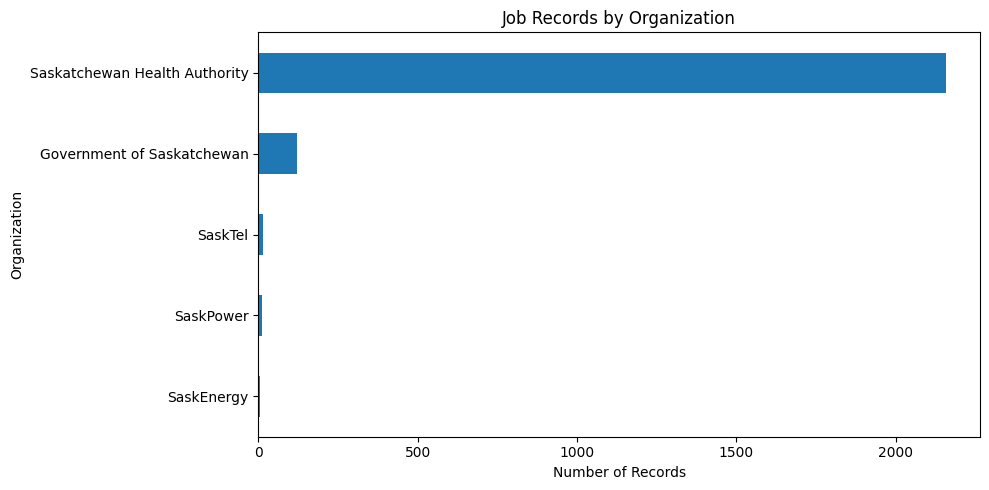

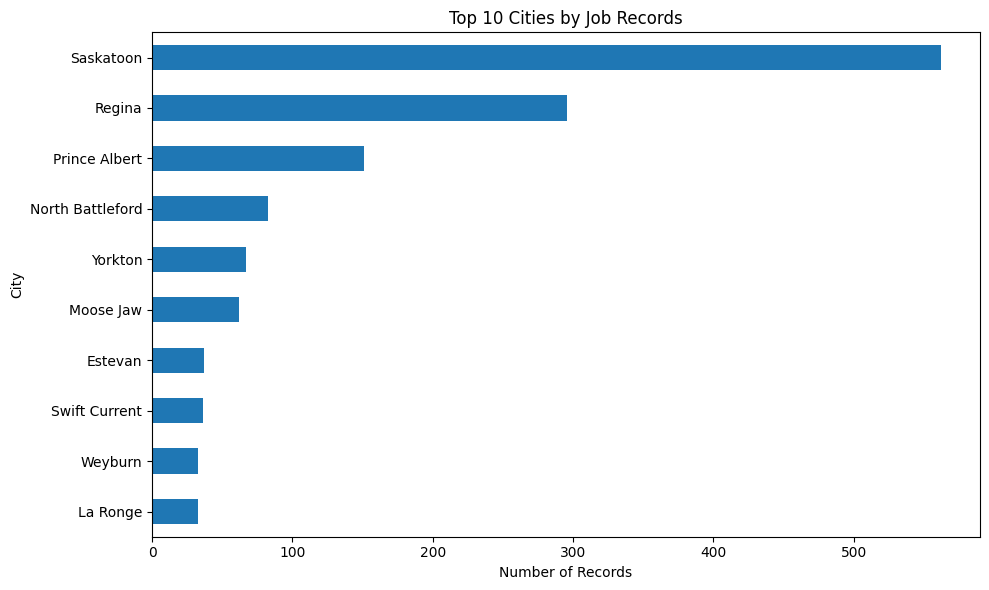

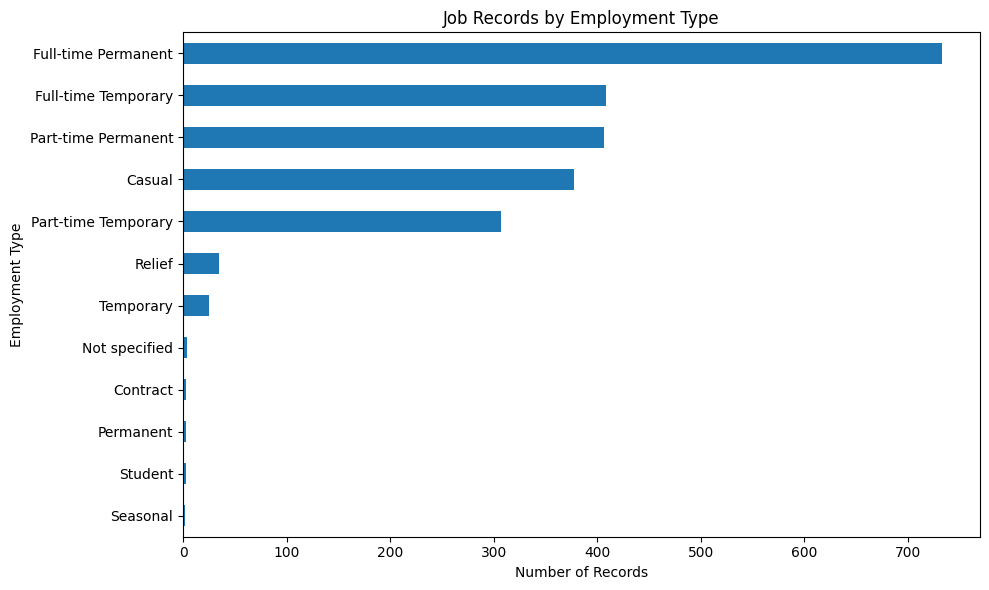

In [11]:

import matplotlib.pyplot as plt

# 1. Records by organization
source_counts = eda_df["Source"].value_counts().sort_values()

plt.figure(figsize=(10, 5))
source_counts.plot(kind="barh")
plt.title("Job Records by Organization")
plt.xlabel("Number of Records")
plt.ylabel("Organization")
plt.tight_layout()
plt.show()

# 2. Top 10 cities
city_counts = (
    eda_df["City"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
city_counts.plot(kind="barh")
plt.title("Top 10 Cities by Job Records")
plt.xlabel("Number of Records")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# 3. Employment type
employment_col = (
    "Employment_Type_Standardized"
    if "Employment_Type_Standardized" in eda_df.columns
    else "Employment_Type"
)

employment_counts = eda_df[employment_col].fillna("Not specified").value_counts()

plt.figure(figsize=(10, 6))
employment_counts.sort_values().plot(kind="barh")
plt.title("Job Records by Employment Type")
plt.xlabel("Number of Records")
plt.ylabel("Employment Type")
plt.tight_layout()
plt.show()


In [12]:

print("Salary unit counts:")
display(eda_df["Salary_Unit_Original"].value_counts(dropna=False))

print("\nSalary range examples by unit:")
display(
    eda_df[
        ["Source", "Job_Title", "Salary_Range",
         "Salary_Min", "Salary_Max", "Salary_Unit_Original"]
    ]
    .dropna(subset=["Salary_Min", "Salary_Max"])
    .groupby("Salary_Unit_Original", dropna=False)
    .head(5)
)


Salary unit counts:


Salary_Unit_Original
Hourly (inferred)    2243
NaN                    35
Hourly                 16
Monthly                 7
Annual (inferred)       7
Name: count, dtype: int64


Salary range examples by unit:


,Source,Job_Title,Salary_Range,Salary_Min,Salary_Max,Salary_Unit_Original
0,Government of Saskatchewan,Child Protection Worker,36.703 - 45.993,36.703,45.993,Hourly (inferred)
1,Government of Saskatchewan,Child Protection Worker,36.703 - 45.993,36.703,45.993,Hourly (inferred)
2,Government of Saskatchewan,Park Manager,47.559 - 61.833,47.559,61.833,Hourly (inferred)
3,Government of Saskatchewan,Park Administrative Supervisor,30.329 - 38.009,30.329,38.009,Hourly (inferred)
4,Government of Saskatchewan,Child Protection Worker,36.703 - 45.993,36.703,45.993,Hourly (inferred)
54,Government of Saskatchewan,Legal Counsel,"$8,523.50 - $16,861.96 monthly",8523.500,16861.960,Monthly
62,Government of Saskatchewan,Crown Prosecutor,8523.50-16861.96,8523.500,16861.960,Monthly
107,Government of Saskatchewan,Public Guardian and Trustee,14797.99 - 19242.85,14797.990,19242.850,Monthly
110,Government of Saskatchewan,Senior Labour Relations Consultant,"$8,650-$11,243",8650.000,11243.000,Monthly
113,Government of Saskatchewan,Legal Counsel,"8,523.50 - 16,861.96",8523.500,16861.960,Monthly


Records with explicitly stated hourly units: 16


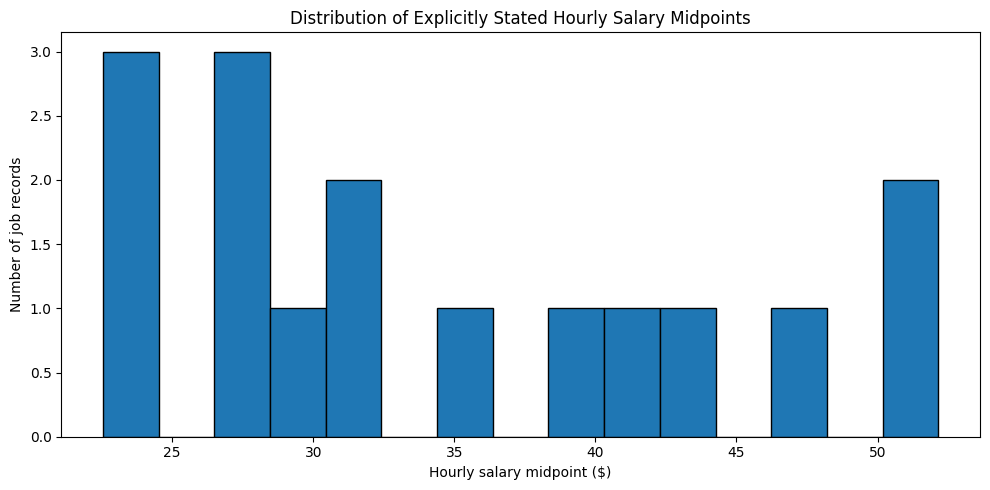

In [ ]:
we

               count      mean   std       min       25%       50%       75%  \
Verified_Unit                                                                  
Hourly          16.0     34.81  9.97     22.55     27.83     31.53     42.31   
Monthly          2.0  12692.73  0.00  12692.73  12692.73  12692.73  12692.73   

                    max  
Verified_Unit            
Hourly            52.15  
Monthly        12692.73  


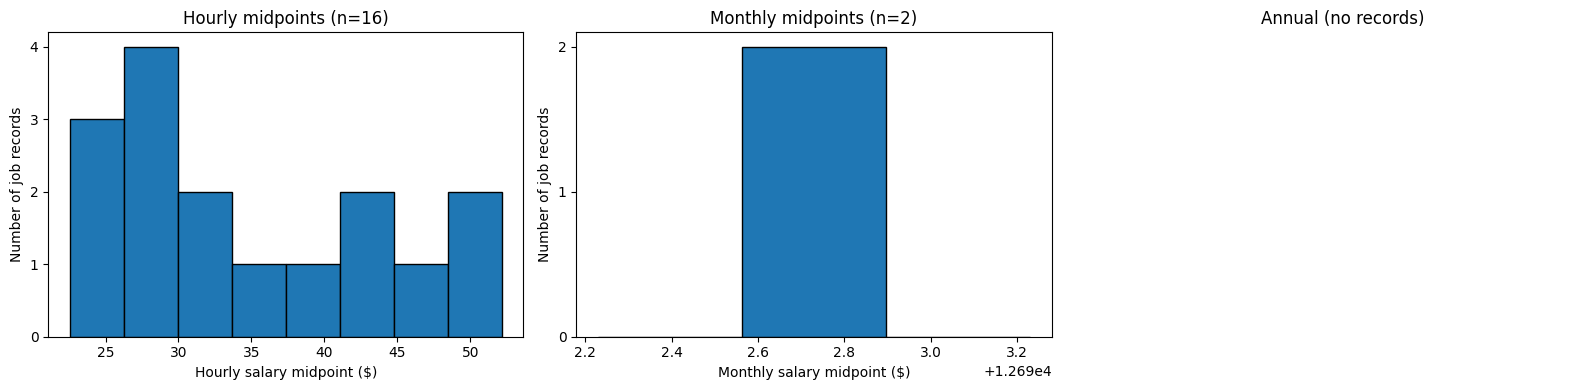

               count      mean      std       min       25%       50%  \
Verified_Unit                                                           
Hourly          16.0   72410.0  20730.0   46904.0   57892.0   65582.0   
Monthly          2.0  152313.0      0.0  152313.0  152313.0  152313.0   

                    75%       max  
Verified_Unit                      
Hourly          88007.0  108472.0  
Monthly        152313.0  152313.0  


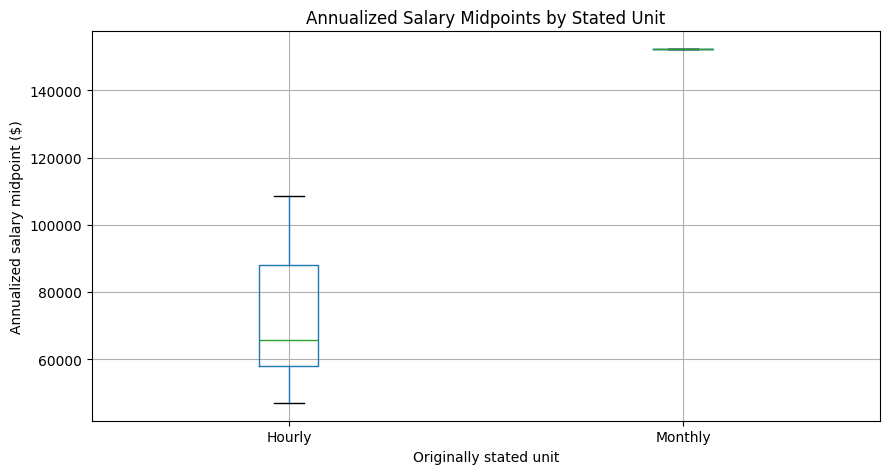

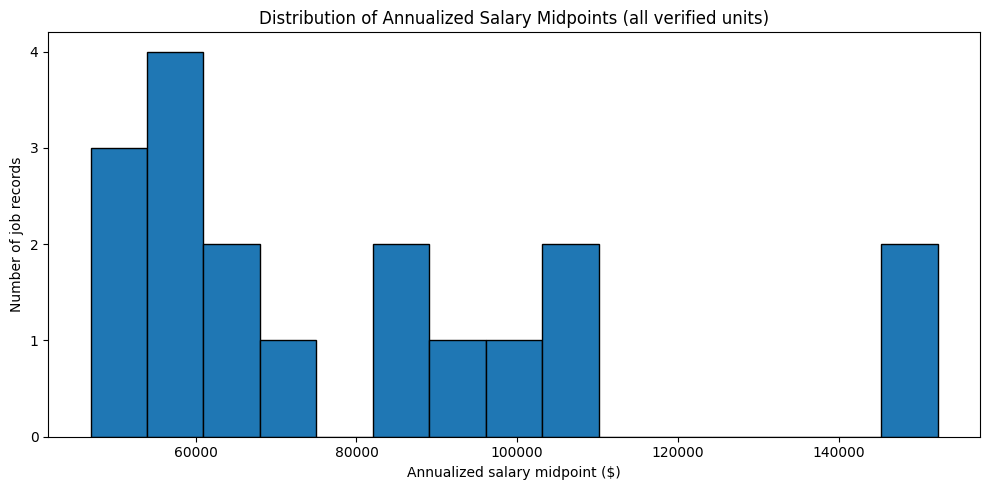

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# 1. Keep only rows with a verified unit and a usable min/max
valid = salary_eda[
    salary_eda["Verified_Unit"].isin(["Hourly", "Monthly", "Annual"])
    & salary_eda["Salary_Min"].notna()
    & salary_eda["Salary_Max"].notna()
].copy()

valid["Salary_Midpoint"] = (valid["Salary_Min"] + valid["Salary_Max"]) / 2

# 2. Summary per unit (check ranges before converting anything)
print(valid.groupby("Verified_Unit")["Salary_Midpoint"].describe().round(2))

# 3. One histogram per unit, with fewer bins and integer y-axis
units = ["Hourly", "Monthly", "Annual"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, unit in zip(axes, units):
    data = valid.loc[valid["Verified_Unit"] == unit, "Salary_Midpoint"]
    if data.empty:
        ax.set_title(f"{unit} (no records)")
        ax.axis("off")
        continue
    ax.hist(data, bins=min(8, max(3, len(data) // 2)), edgecolor="black")
    ax.set_title(f"{unit} midpoints (n={len(data)})")
    ax.set_xlabel(f"{unit} salary midpoint ($)")
    ax.set_ylabel("Number of job records")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

# 4. Normalize to annual (assumes 2,080 hrs/yr = 40 hrs x 52 weeks)
HOURS_PER_YEAR = 2080
multiplier = {"Hourly": HOURS_PER_YEAR, "Monthly": 12, "Annual": 1}

valid["Annual_Min"] = valid["Salary_Min"] * valid["Verified_Unit"].map(multiplier)
valid["Annual_Max"] = valid["Salary_Max"] * valid["Verified_Unit"].map(multiplier)
valid["Annual_Midpoint"] = (valid["Annual_Min"] + valid["Annual_Max"]) / 2

# 5. Sanity check: do the converted values overlap across units?
print(valid.groupby("Verified_Unit")["Annual_Midpoint"].describe().round(0))

# 6. Boxplot of annualized midpoints by unit
fig, ax = plt.subplots(figsize=(9, 5))
valid.boxplot(column="Annual_Midpoint", by="Verified_Unit", ax=ax)
ax.set_title("Annualized Salary Midpoints by Stated Unit")
plt.suptitle("")
ax.set_xlabel("Originally stated unit")
ax.set_ylabel("Annualized salary midpoint ($)")
plt.tight_layout()
plt.show()

# 7. Overall annualized distribution
plt.figure(figsize=(10, 5))
plt.hist(valid["Annual_Midpoint"], bins=15, edgecolor="black")
plt.title("Distribution of Annualized Salary Midpoints (all verified units)")
plt.xlabel("Annualized salary midpoint ($)")
plt.ylabel("Number of job records")
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

Total rows: 2308
Rows with numeric min/max: 2273
Verified_Unit
<NA>       2290
Hourly       16
Monthly       2
Name: count, dtype: int64

Unverified rows with numeric salary: 2255
2071        Pay Band 17 $38.860 to $41.640 (3 step range)
587         Pay Band 12 $23.170 to $24.840 (3 step range)
636                   Pay Band Nurse A $38.580 to $50.070
1952        Pay Band 15 $33.440 to $35.830 (3 step range)
2106        Pay Band 13 $27.990 to $30.000 (3 step range)
6                                         36.703 - 45.993
1576        Pay Band 16 $36.160 to $38.720 (3 step range)
692         Pay Band 16 $36.160 to $38.720 (3 step range)
915         Pay Band 17 $38.860 to $41.640 (3 step range)
1160        Pay Band 12 $23.170 to $24.840 (3 step range)
1523      Pay Band Pharmacist - Degree $51.369 to $59.751
1297                  Pay Band Nurse A $38.580 to $50.070
460         Pay Band 16 $36.160 to $38.720 (3 step range)
2128    Pay Band Psychologist - Masters $44.093 to $53...
1304    

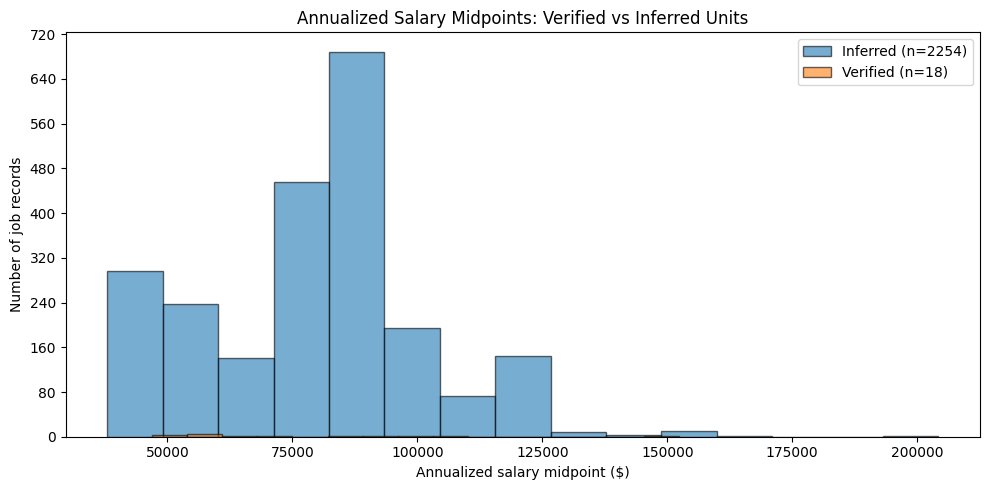

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# 1. How much of the dataset is usable?
total = len(salary_eda)
has_range = salary_eda["Salary_Min"].notna() & salary_eda["Salary_Max"].notna()
print(f"Total rows: {total}")
print(f"Rows with numeric min/max: {has_range.sum()}")
print(salary_eda["Verified_Unit"].value_counts(dropna=False))

# 2. What do unverified rows look like? (send me this output)
unverified = salary_eda[salary_eda["Verified_Unit"].isna() & has_range]
print("\nUnverified rows with numeric salary:", len(unverified))
print(unverified["Salary_Range"].sample(min(15, len(unverified)), random_state=1).to_string())

# 3. Check the two monthly rows for duplicates
id_cols = [c for c in ["Job_Title", "Company", "Location", "Salary_Range"] if c in salary_eda.columns]
print("\nMonthly rows:")
print(salary_eda.loc[salary_eda["Verified_Unit"] == "Monthly", id_cols])

# 4. Inferred unit by magnitude (kept separate from Verified_Unit)
mid = (salary_eda["Salary_Min"] + salary_eda["Salary_Max"]) / 2
salary_eda["Inferred_Unit"] = np.select(
    [mid.between(10, 200), mid.between(2000, 20000), mid >= 30000],
    ["Hourly", "Monthly", "Annual"],
    default=None,
)
salary_eda["Final_Unit"] = salary_eda["Verified_Unit"].where(
    salary_eda["Verified_Unit"].isin(["Hourly", "Monthly", "Annual"]),
    salary_eda["Inferred_Unit"],
)
salary_eda["Unit_Source"] = np.where(
    salary_eda["Verified_Unit"].isin(["Hourly", "Monthly", "Annual"]), "Verified",
    np.where(salary_eda["Inferred_Unit"].notna(), "Inferred", "Unresolved"),
)
print("\n", pd.crosstab(salary_eda["Final_Unit"].fillna("None"), salary_eda["Unit_Source"]))

# 5. Annualize everything with a resolved unit
mult = {"Hourly": 2080, "Monthly": 12, "Annual": 1}
full = salary_eda[salary_eda["Final_Unit"].notna() & has_range].copy()
full["Annual_Midpoint"] = (
    (full["Salary_Min"] + full["Salary_Max"]) / 2 * full["Final_Unit"].map(mult)
)

# 6. Histogram colored by how the unit was determined
fig, ax = plt.subplots(figsize=(10, 5))
for src, grp in full.groupby("Unit_Source"):
    ax.hist(grp["Annual_Midpoint"], bins=15, alpha=0.6, label=f"{src} (n={len(grp)})", edgecolor="black")
ax.set_title("Annualized Salary Midpoints: Verified vs Inferred Units")
ax.set_xlabel("Annualized salary midpoint ($)")
ax.set_ylabel("Number of job records")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
plt.tight_layout()
plt.show()

Odd rows: 12
                                                                                          Salary_Range  Salary_Min  Salary_Max    Mid_Raw Final_Unit
62                                                                                    8523.50-16861.96     8523.50    16861.96   12692.73    Monthly
107                                                                                14797.99 - 19242.85    14797.99    19242.85   17020.42    Monthly
110                                                                                     $8,650-$11,243     8650.00    11243.00    9946.50    Monthly
113                                                                               8,523.50 - 16,861.96     8523.50    16861.96   12692.73    Monthly
115                                                                                  22808.0 - 29649.0    22808.00    29649.00   26228.50       None
2202  $102,550 to $122,674 (based on years of experience) Competitive Health Benefits and Pen

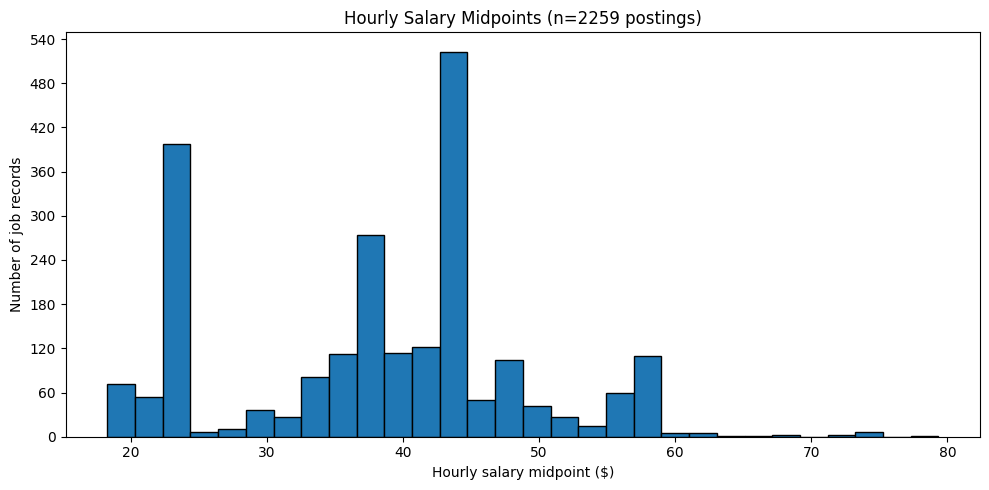

                                       postings  median_mid  min_mid  max_mid
Pay_Band                                                                     
Nurse A                                     451       44.32    44.32    44.32
16                                          312       37.44    37.44    39.61
12                                          212       24.01    24.01    46.08
No band label                               136       38.72    22.35    72.80
11                                          129       23.40    23.40    24.20
Nurse Practitioner                          107       57.75    57.75    57.75
14                                           99       34.92    31.80    34.92
Nurse B                                      73       47.24    47.24    48.18
Emergency Medical Technician                 70       33.24    33.24    33.24
17                                           65       42.06    40.25    42.06
Occupational Therapist - Degree              51       42.51    4

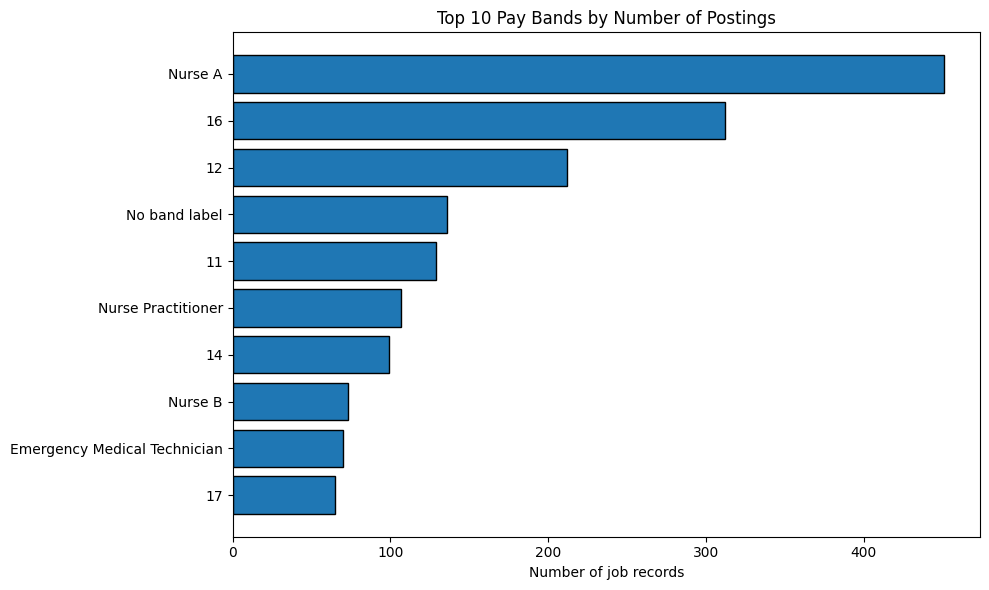

              count   mean    std    min    25%    50%    75%    max
Unit_Source                                                         
Inferred     2243.0  38.42  10.77  18.26  29.30  39.42  44.32  79.34
Verified       16.0  34.81   9.97  22.55  27.83  31.53  42.31  52.15


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

has_range = salary_eda["Salary_Min"].notna() & salary_eda["Salary_Max"].notna()
salary_eda["Mid_Raw"] = (salary_eda["Salary_Min"] + salary_eda["Salary_Max"]) / 2

# 1. Inspect the odd groups: inferred monthly/annual, and unresolved rows that DO have numbers
odd = salary_eda[
    (salary_eda["Unit_Source"].eq("Inferred") & salary_eda["Final_Unit"].isin(["Monthly", "Annual"]))
    | (salary_eda["Unit_Source"].eq("Unresolved") & has_range)
]
print("Odd rows:", len(odd))
print(odd[["Salary_Range", "Salary_Min", "Salary_Max", "Mid_Raw", "Final_Unit"]]
      .drop_duplicates("Salary_Range").to_string())

# 2. Pull the pay band label out of the text (e.g. "17", "Nurse A", "Pharmacist - Degree")
salary_eda["Pay_Band"] = (
    salary_eda["Salary_Range"].astype(str)
    .str.extract(r"(?i)pay band\s+(.+?)\s+\$", expand=False)
    .str.strip()
)
salary_eda["Pay_Band"] = salary_eda["Pay_Band"].fillna("No band label")

# 3. Main analysis set: hourly rows only (verified + inferred)
hourly_all = salary_eda[(salary_eda["Final_Unit"] == "Hourly") & has_range].copy()
hourly_all["Hourly_Midpoint"] = hourly_all["Mid_Raw"]
print("\nHourly records:", len(hourly_all))
print(hourly_all["Hourly_Midpoint"].describe().round(2))
print("Distinct salary strings:", hourly_all["Salary_Range"].nunique())

# 4. Overall distribution
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(hourly_all["Hourly_Midpoint"], bins=30, edgecolor="black")
ax.set_title(f"Hourly Salary Midpoints (n={len(hourly_all)} postings)")
ax.set_xlabel("Hourly salary midpoint ($)")
ax.set_ylabel("Number of job records")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

# 5. Most common pay bands: posting count and median midpoint
band_summary = (
    hourly_all.groupby("Pay_Band")["Hourly_Midpoint"]
    .agg(postings="count", median_mid="median", min_mid="min", max_mid="max")
    .sort_values("postings", ascending=False)
    .round(2)
)
print(band_summary.head(15))

top = band_summary.head(10).sort_values("postings")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top["postings"], edgecolor="black")
ax.set_title("Top 10 Pay Bands by Number of Postings")
ax.set_xlabel("Number of job records")
plt.tight_layout()
plt.show()

# 6. Verified vs inferred check (do they agree?)
print(hourly_all.groupby("Unit_Source")["Hourly_Midpoint"].describe().round(2))

Analysis rows: 2272 | converted from monthly/annual: 13
       hourly_only  all_converted
count      2259.00        2272.00
mean         38.40          38.54
std          10.77          10.95
min          18.26          18.26
25%          29.30          29.30
50%          39.42          39.42
75%          44.32          44.32
max          79.34          98.19

Top 10 pay ranges:
 Salary_Range
Pay Band Nurse A $38.580 to $50.070                         451
Pay Band 16 $36.160 to $38.720 (3 step range)               242
Pay Band 12 $23.170 to $24.840 (3 step range)               203
Pay Band 11 $22.600 to $24.210 (3 step range)               118
Pay Band Nurse Practitioner $52.590 to $62.910              107
Pay Band 14 $33.740 to $36.110 (3 step range)                87
Pay Band Nurse B $42.040 to $52.440                          70
Pay Band Emergency Medical Technician $29.909 to $36.572     70
Pay Band 10 $22.020 to $23.550 (3 step range)                49
Pay Band 17 $40.610 to $43.5

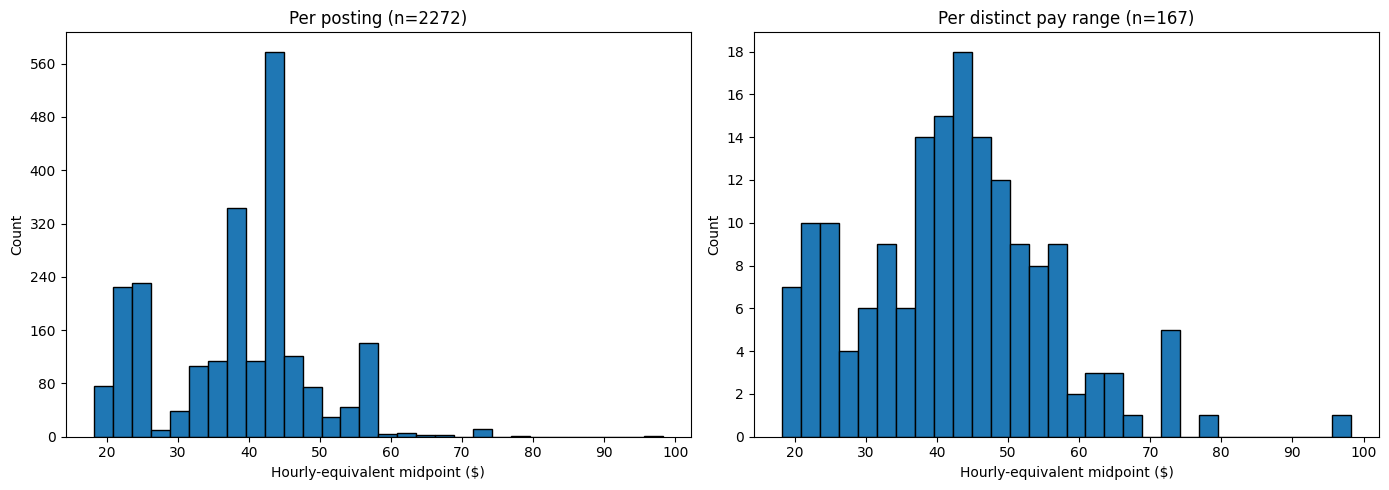


                                        postings  median    q25    q75
Pay_Band                                                             
Psychologist - PhD                           10   73.46  62.79  73.46
Nurse Practitioner                          107   57.75  57.75  57.75
Physician Assistant Degree                   22   56.80  56.80  56.80
Pharmacist - Degree                          23   55.56  55.56  55.56
Nurse C                                      20   50.98  50.98  50.98
Speech Language Pathologist - Masters        34   49.79  48.13  49.79
Physical Therapist - Degree Senior           11   48.30  48.30  48.30
Nurse B                                      73   47.24  47.24  47.24
19                                           17   46.68  46.68  46.68
Physical Therapist - Degree                  27   44.72  44.72  44.72
Nurse A                                     451   44.32  44.32  44.32
Respiratory Therapist - Diploma              25   42.90  42.90  42.90
Occupational Thera

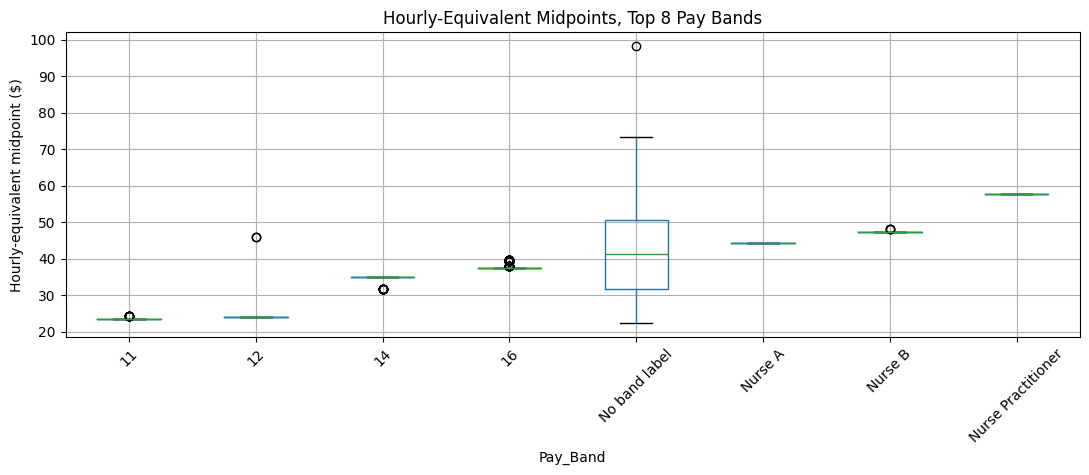


Columns: ['Record_ID', 'Source', 'Job_ID', 'Job_Title', 'Organization', 'Category', 'Job_Function', 'City', 'Province', 'Country', 'Location_Raw', 'Employment_Type', 'Employment_Type_Standardized', 'FTE', 'Union', 'Hours_of_Work', 'Salary_Range', 'Salary_Min', 'Salary_Max', 'Salary_Unit', 'Salary_Status', 'Number_of_Openings', 'Posting_Date', 'Closing_Date', 'Description', 'Qualifications', 'Responsibilities', 'Job_URL', 'Collection_Date', 'Salary_Unit_Original', 'Salary_Unit_Analysis', 'Salary_Range_Text', 'Verified_Unit', 'Inferred_Unit', 'Final_Unit', 'Unit_Source', 'Mid_Raw', 'Pay_Band', 'Hourly_Equiv', 'Is_Hourly_Native']


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# 1. Hourly-equivalent for every row with a resolved unit (2,080 hrs/yr assumption)
HOURS_PER_YEAR = 2080
to_hourly = {"Hourly": 1, "Monthly": 12 / HOURS_PER_YEAR, "Annual": 1 / HOURS_PER_YEAR}
salary_eda["Hourly_Equiv"] = salary_eda["Mid_Raw"] * salary_eda["Final_Unit"].map(to_hourly)

analysis = salary_eda[salary_eda["Hourly_Equiv"].notna()].copy()
analysis["Is_Hourly_Native"] = analysis["Final_Unit"].eq("Hourly")
print("Analysis rows:", len(analysis), "| converted from monthly/annual:", (~analysis["Is_Hourly_Native"]).sum())

# 2. Sensitivity check: do the converted rows change anything?
print(pd.DataFrame({
    "hourly_only": analysis.loc[analysis["Is_Hourly_Native"], "Hourly_Equiv"].describe(),
    "all_converted": analysis["Hourly_Equiv"].describe(),
}).round(2))

# 3. How concentrated are the postings?
counts = analysis["Salary_Range"].value_counts()
print("\nTop 10 pay ranges:\n", counts.head(10))
print(f"Top 10 ranges cover {counts.head(10).sum() / len(analysis):.1%} of postings")

# 4. Two views of the distribution: per posting vs per distinct pay range
levels = analysis.drop_duplicates("Salary_Range")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
axes[0].hist(analysis["Hourly_Equiv"], bins=30, edgecolor="black")
axes[0].set_title(f"Per posting (n={len(analysis)})")
axes[1].hist(levels["Hourly_Equiv"], bins=30, edgecolor="black")
axes[1].set_title(f"Per distinct pay range (n={len(levels)})")
for ax in axes:
    ax.set_xlabel("Hourly-equivalent midpoint ($)")
    ax.set_ylabel("Count")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

# 5. Reusable group comparison (ignores tiny groups)
def group_summary(df, col, min_n=10, top=15):
    g = (df.groupby(col)["Hourly_Equiv"]
           .agg(postings="count", median="median",
                q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
           .round(2))
    return g[g["postings"] >= min_n].sort_values("median", ascending=False).head(top)

print("\n", group_summary(analysis, "Pay_Band"))

# 6. Spread within the most common pay bands
top_bands = analysis["Pay_Band"].value_counts().head(8).index
analysis[analysis["Pay_Band"].isin(top_bands)].boxplot(
    column="Hourly_Equiv", by="Pay_Band", rot=45, figsize=(11, 5))
plt.suptitle("")
plt.title("Hourly-Equivalent Midpoints, Top 8 Pay Bands")
plt.ylabel("Hourly-equivalent midpoint ($)")
plt.tight_layout()
plt.show()

# 7. Which columns could we group by next?
print("\nColumns:", analysis.columns.tolist())

Shape: (2308, 39)
Record_ID                        object
Source                           object
Job_ID                           object
Job_Title                        object
Organization                     object
Category                         object
Job_Function                     object
City                             object
Province                         object
Country                          object
Location_Raw                     object
Employment_Type                  object
Employment_Type_Standardized     object
FTE                             float64
Union                            object
Hours_of_Work                    object
Salary_Range                     object
Salary_Min                      float64
Salary_Max                      float64
Salary_Unit                      object
Salary_Status                    object
Number_of_Openings              float64
Posting_Date                     object
Closing_Date                     object
Description           

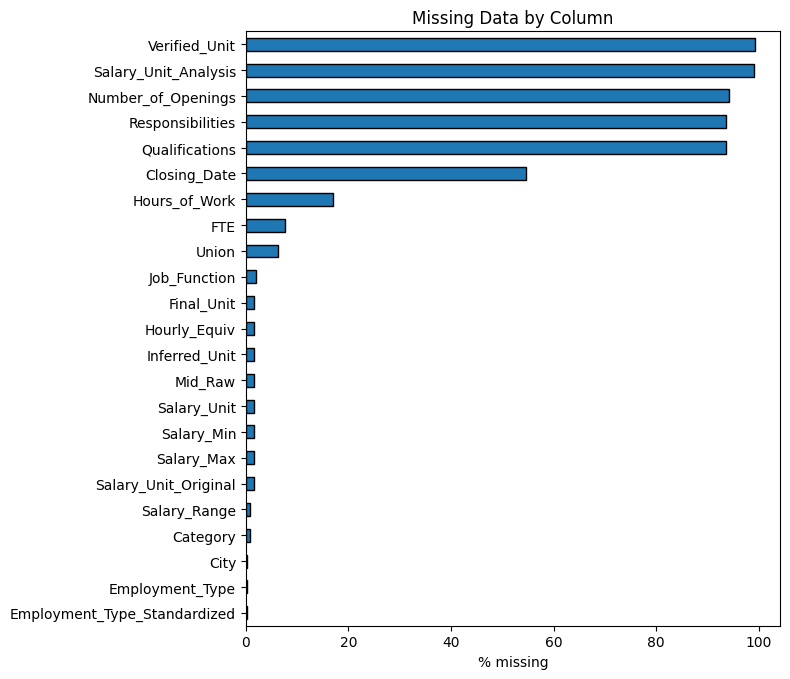


                      count    mean      std    min    25%    50%    75%  \
FTE                 2132.0    0.68     0.39   0.00   0.47   0.83   1.00   
Salary_Min          2273.0  355.09  5204.81  17.63  27.99  38.07  38.65   
Salary_Max          2273.0  485.93  7135.27  18.90  32.59  41.81  50.07   
Number_of_Openings   133.0    1.56     1.52   1.00   1.00   1.00   1.00   
Hourly_Equiv        2272.0   38.54    10.95  18.26  29.30  39.42  44.32   

                          max  
FTE                      1.00  
Salary_Min          112402.00  
Salary_Max          161224.00  
Number_of_Openings      12.00  
Hourly_Equiv            98.19  


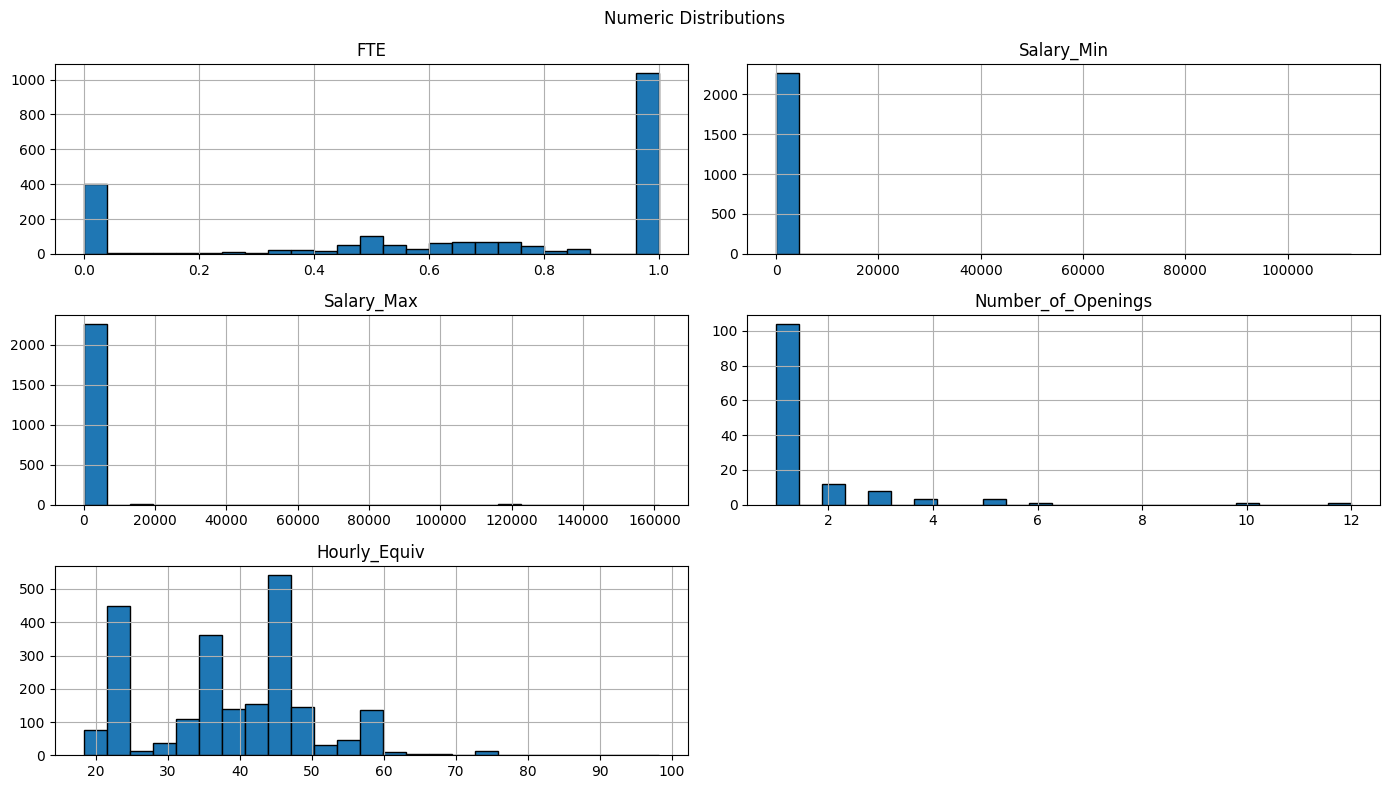


Record_ID: 2308 unique
Record_ID
GOV_SK_100083    1
GOV_SK_100217    1
GOV_SK_100766    1
GOV_SK_100768    1
GOV_SK_100906    1
GOV_SK_100059    1
GOV_SK_100117    1
GOV_SK_101179    1
Name: count, dtype: int64

Source: 5 unique
Source
Saskatchewan Health Authority    2156
Government of Saskatchewan        122
SaskTel                            14
SaskPower                          11
SaskEnergy                          5
Name: count, dtype: int64

Job_ID: 2307 unique
Job_ID
101320       2
R00004405    1
R00004348    1
100768       1
7678         1
4816         1
604248017    1
606890217    1
Name: count, dtype: int64

Job_Title: 328 unique
Job_Title
Nurse A - Registered Nurse General Duty Nurse        282
Licensed Practical Nurse                             242
Nurse A - Registered Nurse Registered Psych Nurse    149
Continuing Care Assistant                            134
Nurse Practitioner                                   108
Combined Laboratory & X-Ray Technologist              8

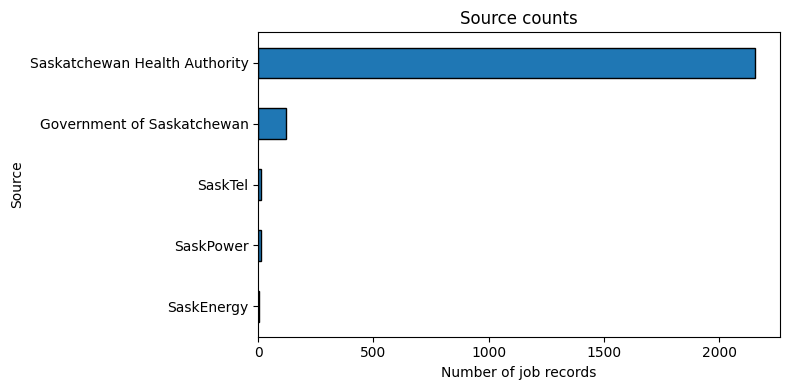

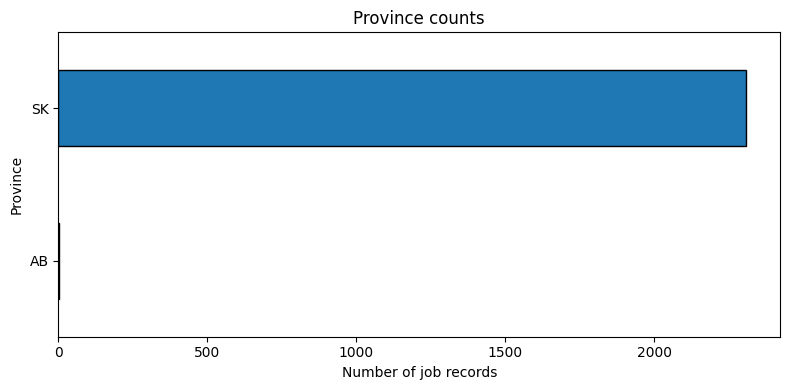

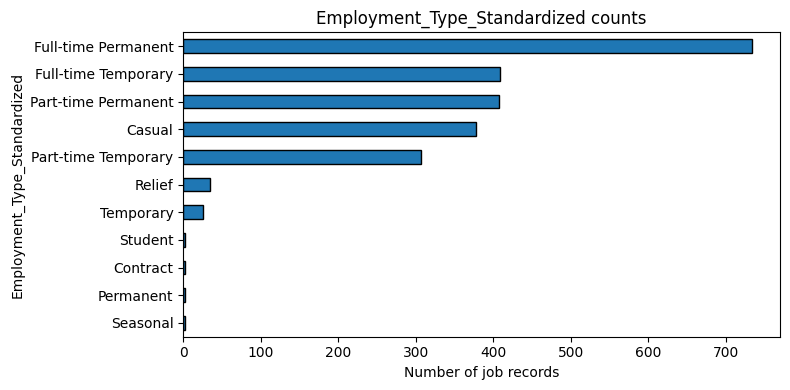

C:\Users\Dell\AppData\Local\Temp\ipykernel_17096\3697875585.py:50: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


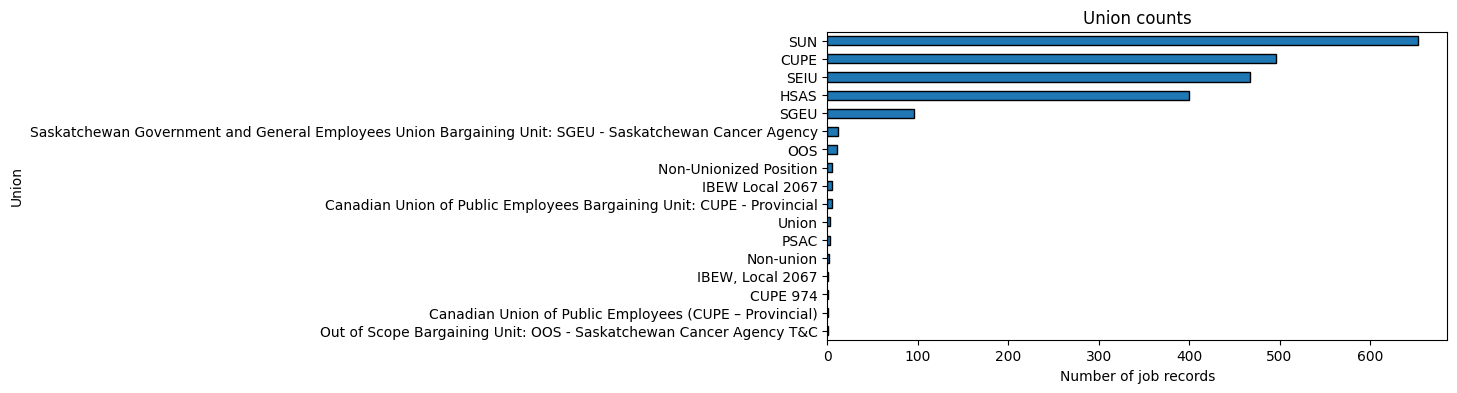

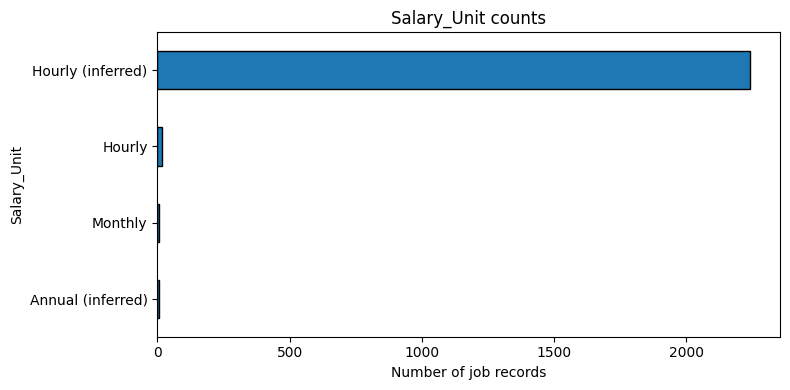

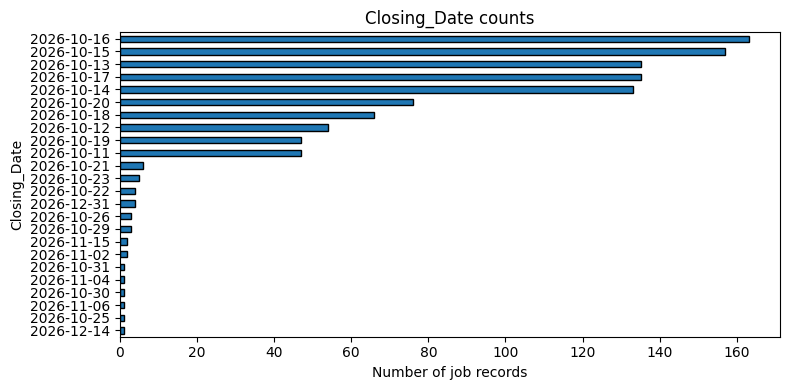

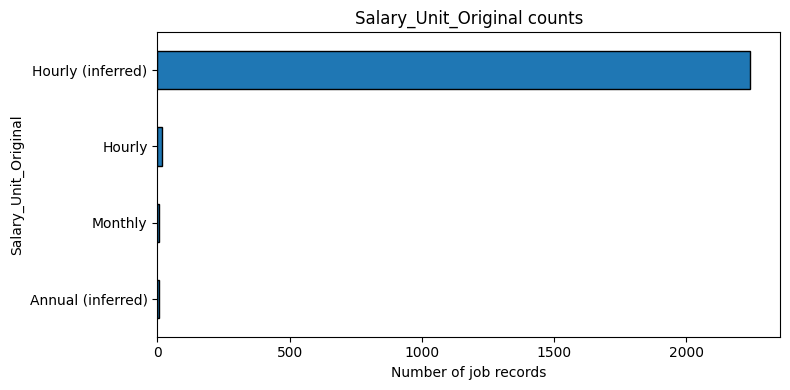

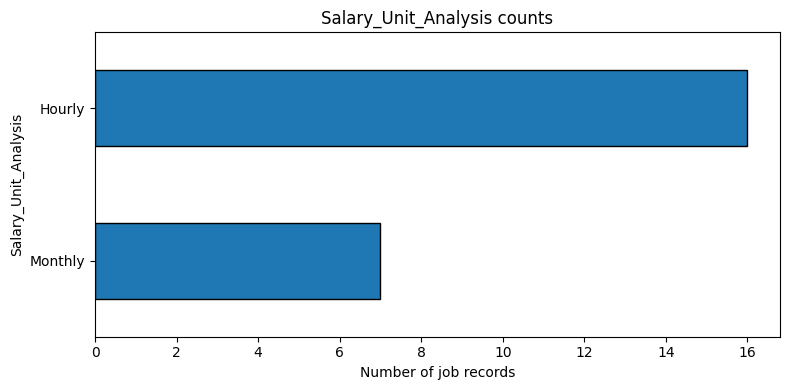

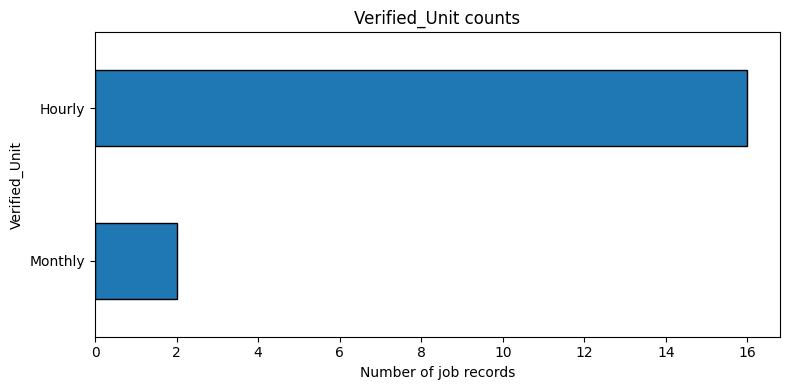

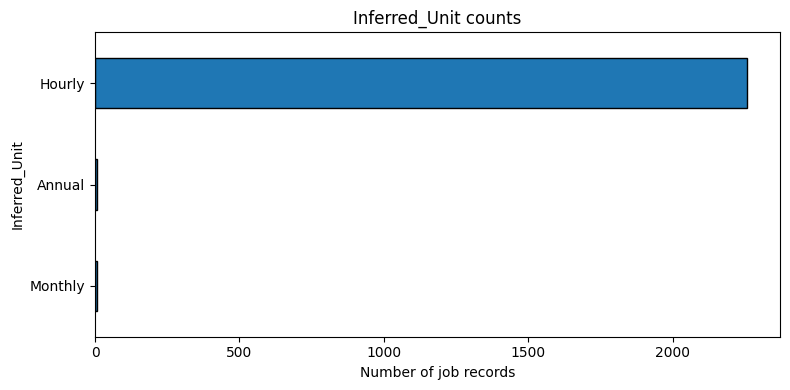

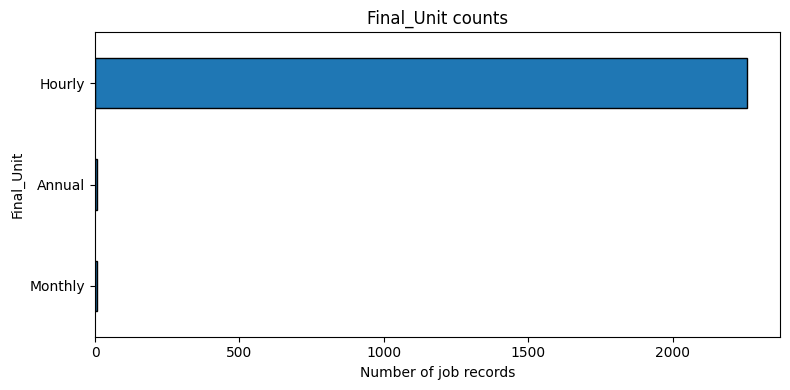

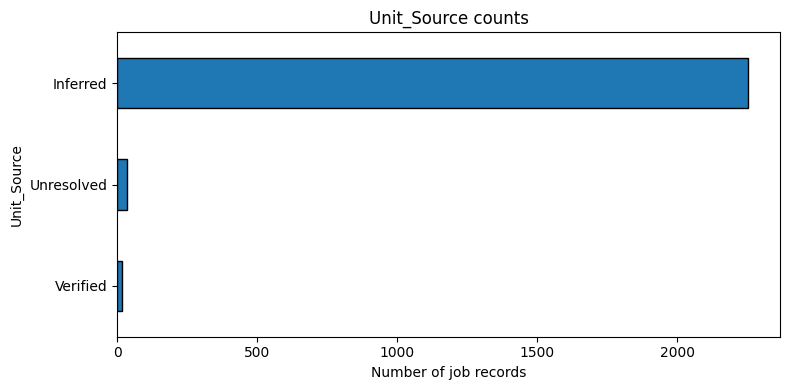

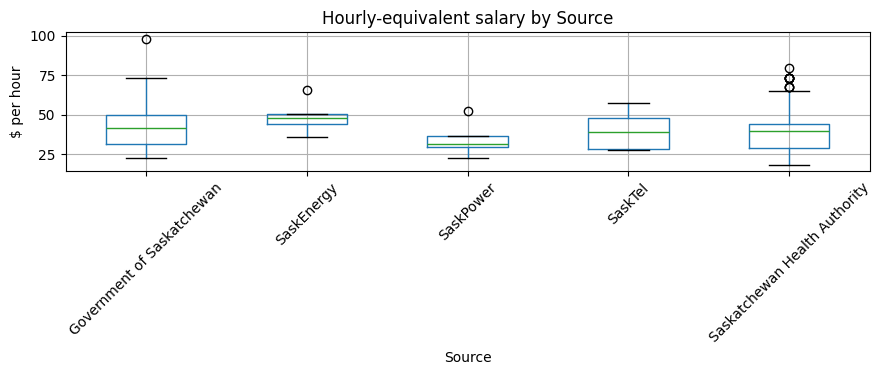

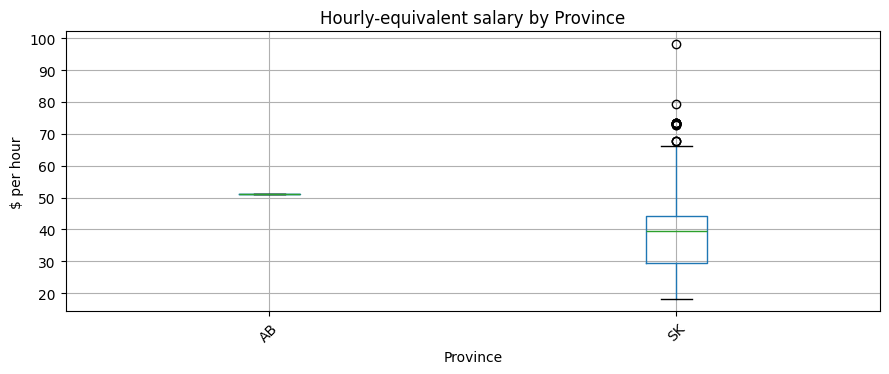

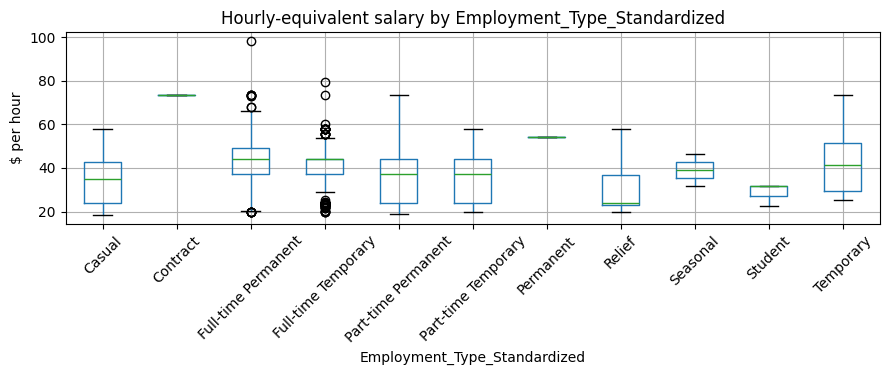

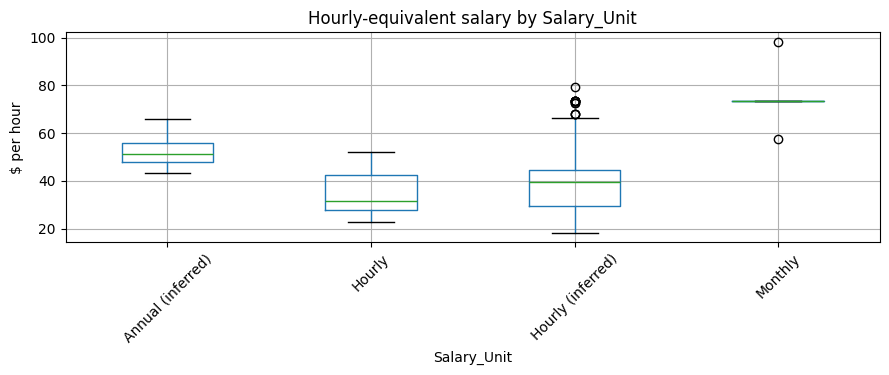

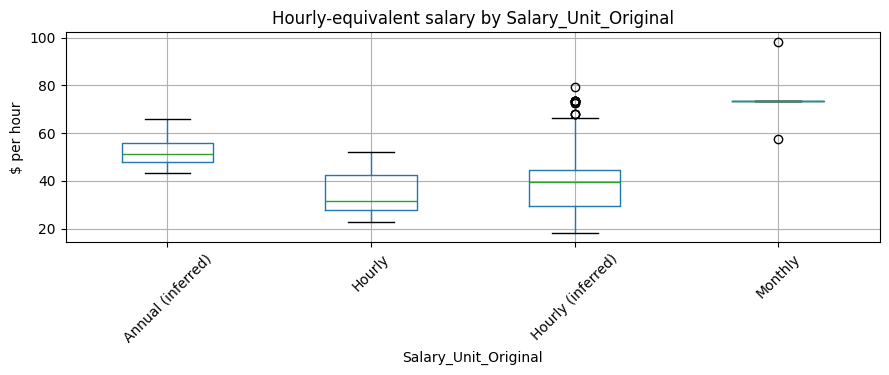

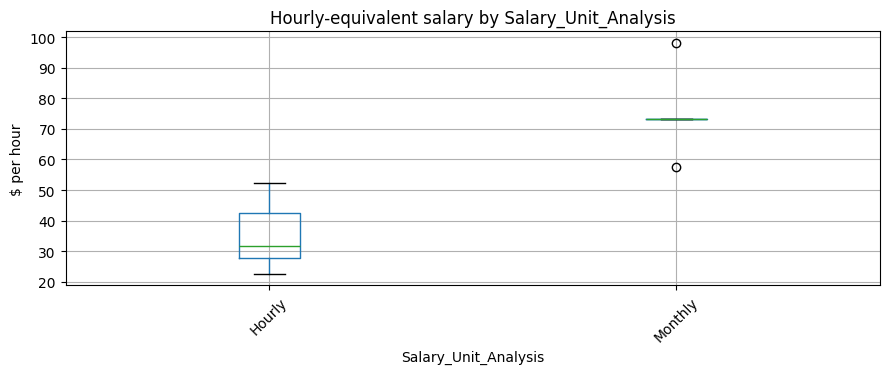

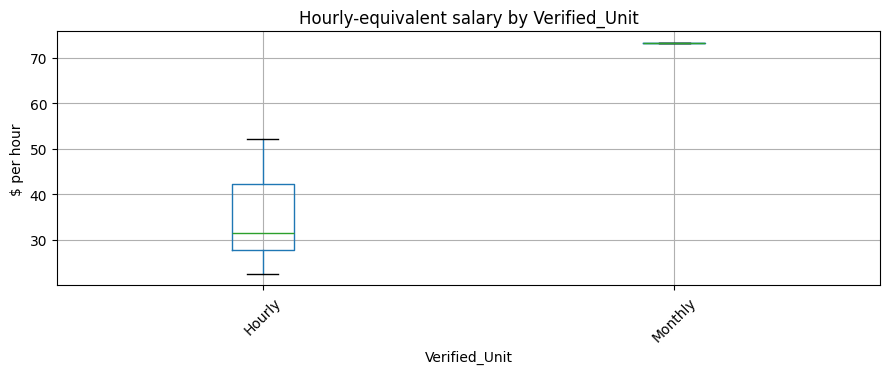

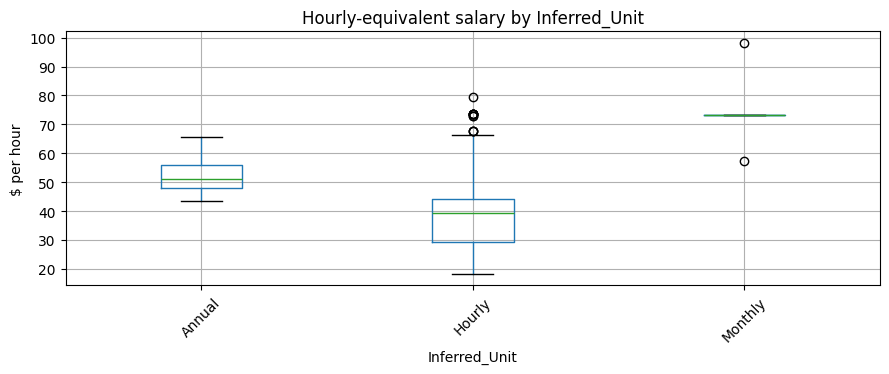

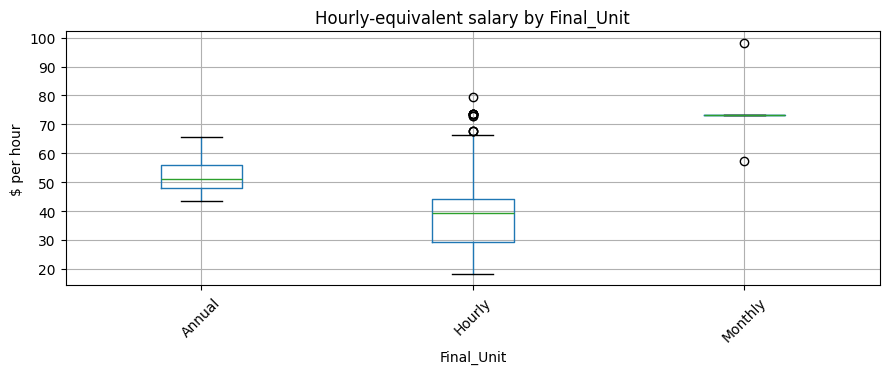

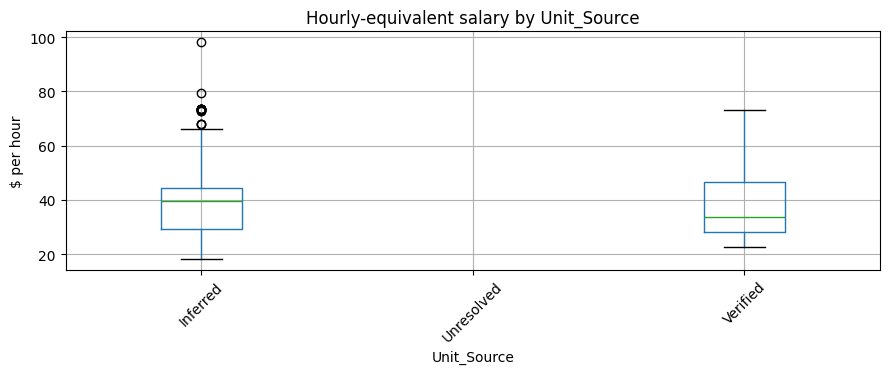

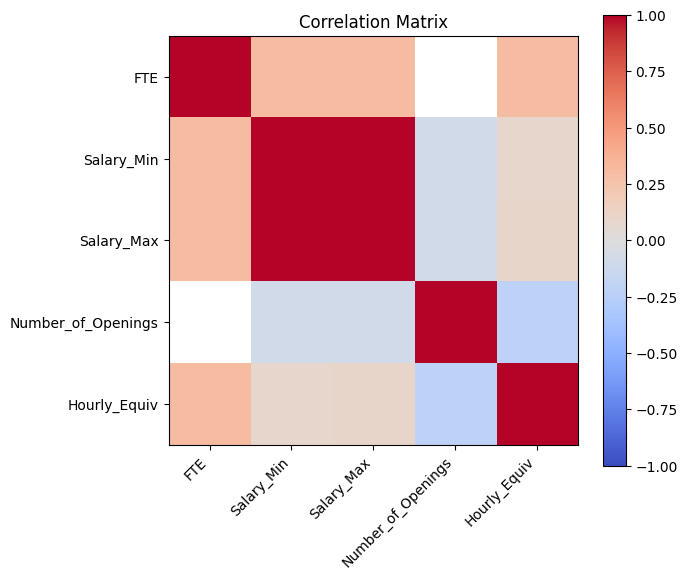


Possible date columns: ['Posting_Date', 'Closing_Date', 'Collection_Date']


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Final analysis frame from the previous step
df = salary_eda.copy()
df["Hourly_Equiv"] = df["Mid_Raw"] * df["Final_Unit"].map(
    {"Hourly": 1, "Monthly": 12 / 2080, "Annual": 1 / 2080}
)

# ---------- 1. Structure ----------
print("Shape:", df.shape)
print(df.dtypes)
print("\nDuplicate rows:", df.duplicated().sum())

# ---------- 2. Missing data ----------
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print("\nMissing % by column:\n", missing[missing > 0])

fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * (missing > 0).sum())))
missing[missing > 0].sort_values().plot.barh(ax=ax, edgecolor="black")
ax.set_xlabel("% missing")
ax.set_title("Missing Data by Column")
plt.tight_layout()
plt.show()

# ---------- 3. Numeric columns ----------
num_cols = df.select_dtypes("number").columns.drop(["Mid_Raw"], errors="ignore")
print("\n", df[num_cols].describe().round(2).T)

df[num_cols].hist(bins=25, figsize=(14, 8), edgecolor="black")
plt.suptitle("Numeric Distributions")
plt.tight_layout()
plt.show()

# ---------- 4. Categorical columns ----------
cat_cols = [c for c in df.select_dtypes(["object", "category"]).columns
            if c not in ["Salary_Range", "Salary_Range_Text"]]
for c in cat_cols:
    print(f"\n{c}: {df[c].nunique()} unique")
    print(df[c].value_counts().head(8))

# Bar charts for low-cardinality categoricals
for c in [c for c in cat_cols if 2 <= df[c].nunique() <= 25]:
    fig, ax = plt.subplots(figsize=(8, 4))
    df[c].value_counts().sort_values().plot.barh(ax=ax, edgecolor="black")
    ax.set_title(f"{c} counts")
    ax.set_xlabel("Number of job records")
    plt.tight_layout()
    plt.show()

# ---------- 5. Salary vs categories ----------
for c in [c for c in cat_cols if 2 <= df[c].nunique() <= 12]:
    df.boxplot(column="Hourly_Equiv", by=c, rot=45, figsize=(9, 4))
    plt.suptitle("")
    plt.title(f"Hourly-equivalent salary by {c}")
    plt.ylabel("$ per hour")
    plt.tight_layout()
    plt.show()

# ---------- 6. Correlations ----------
corr_cols = [c for c in num_cols if df[c].nunique() > 1]
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=45, ha="right")
    ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols)
    fig.colorbar(im)
    ax.set_title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

# ---------- 7. Time trend (if a date column exists) ----------
date_cols = [c for c in df.columns if "date" in c.lower() or "posted" in c.lower()]
print("\nPossible date columns:", date_cols)

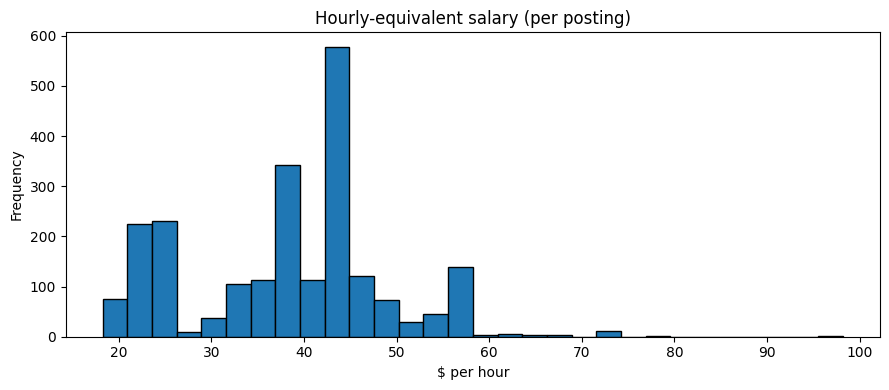

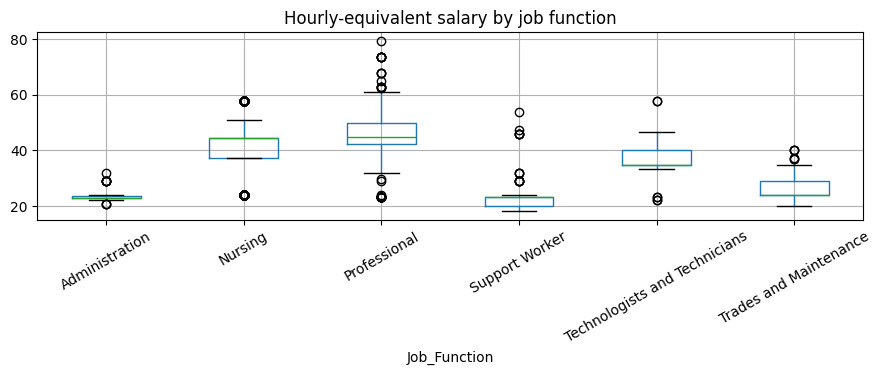

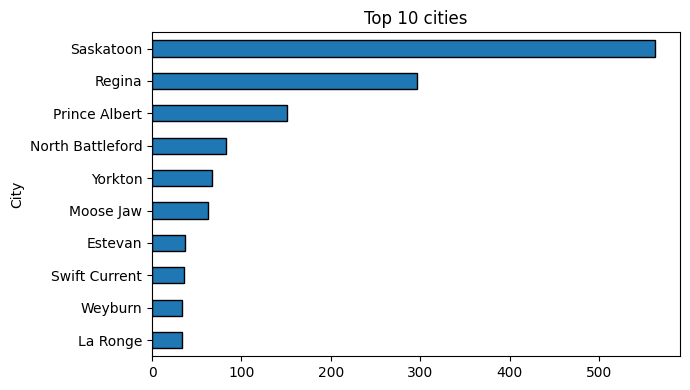

Employment_Type_Standardized
Full-time Permanent    733
Full-time Temporary    408
Part-time Permanent    407
Casual                 378
Part-time Temporary    307
Relief                  35
Temporary               25
Permanent                3
Contract                 3
Student                  3
Seasonal                 2
Name: count, dtype: int64
Union_Clean
SUN          653
CUPE         503
SEIU         467
HSAS         400
SGEU         108
OOS           12
Non-union      7
IBEW           6
Name: count, dtype: int64
      Job_ID                                          Job_Title  \
61    101320                                   Postal Chauffeur   
1477  101320  Medical Radiation Technologist Working Supervisor   

                    Organization  
61    SaskBuilds and Procurement  
1477  Battlefords Union Hospital  
                        Job_Title  \
107   Public Guardian and Trustee   
1636      Psychologist PhD Senior   
1058             Psychologist PhD   
1521             Ps

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = salary_eda.copy()
df["Hourly_Equiv"] = df["Mid_Raw"] * df["Final_Unit"].map(
    {"Hourly": 1, "Monthly": 12 / 2080, "Annual": 1 / 2080})

# Cleaning: merge the duplicate union labels
def clean_union(u):
    if pd.isna(u): return np.nan
    s = u.lower()
    for key, name in [("sgeu", "SGEU"), ("cupe", "CUPE"), ("canadian union of public", "CUPE"),
                      ("ibew", "IBEW"), ("oos", "OOS"), ("out of scope", "OOS")]:
        if key in s: return name
    if "non-union" in s or "non union" in s: return "Non-union"
    return u.strip()
df["Union_Clean"] = df["Union"].apply(clean_union)

# 1. Salary distribution (the one salary chart you need)
df["Hourly_Equiv"].plot.hist(bins=30, edgecolor="black", figsize=(9, 4),
                             title="Hourly-equivalent salary (per posting)")
plt.xlabel("$ per hour"); plt.tight_layout(); plt.show()

# 2. Salary by job function (top 6 groups by size)
top = df["Job_Function"].value_counts().head(6).index
df[df["Job_Function"].isin(top)].boxplot(column="Hourly_Equiv", by="Job_Function",
                                         rot=30, figsize=(9, 4))
plt.suptitle(""); plt.title("Hourly-equivalent salary by job function")
plt.tight_layout(); plt.show()

# 3. Top 10 cities by postings
df["City"].value_counts().head(10).sort_values().plot.barh(
    figsize=(7, 4), edgecolor="black", title="Top 10 cities")
plt.tight_layout(); plt.show()

# 4. Employment type and union (tables only, no charts)
print(df["Employment_Type_Standardized"].value_counts())
print(df["Union_Clean"].value_counts().head(8))

# 5. One data-quality check: odd rows
print(df[df["Job_ID"].duplicated(keep=False)][["Job_ID", "Job_Title", "Organization"]])
print(df.nlargest(5, "Hourly_Equiv")[["Job_Title", "Salary_Range", "Final_Unit", "Hourly_Equiv"]])

In [21]:
summary = (df.groupby("Job_Function")["Hourly_Equiv"]
             .agg(postings="count", median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
             .round(2).sort_values("postings", ascending=False).head(8))
print(summary)

                               postings  median    q25    q75
Job_Function                                                 
Nursing                             997   44.32  37.44  44.32
Professional                        361   44.72  42.35  49.79
Technologists and Technicians       340   34.92  34.64  40.25
Support Worker                      261   23.40  20.20  23.40
Trades and Maintenance               69   24.01  24.01  28.99
Administration                       55   22.78  22.78  23.70
Clinical Professional                38   47.24  47.24  47.24
Human Services                       36   41.35  38.43  42.64


In [22]:
print(df.groupby("Source")[["Qualifications", "Responsibilities"]].agg(lambda s: s.notna().mean()).round(2))

                               Qualifications  Responsibilities
Source                                                         
Government of Saskatchewan               1.00              1.00
SaskEnergy                               1.00              0.80
SaskPower                                0.73              0.73
SaskTel                                  0.86              0.86
Saskatchewan Health Authority            0.00              0.00


In [23]:
print(df.groupby("Source")[["Number_of_Openings", "Closing_Date", "FTE", "Union", "Hours_of_Work"]]
        .agg(lambda s: s.notna().mean()).round(2))

                               Number_of_Openings  Closing_Date   FTE  Union  \
Source                                                                         
Government of Saskatchewan                   1.00          1.00  0.00   0.00   
SaskEnergy                                   0.00          1.00  0.00   1.00   
SaskPower                                    0.00          1.00  0.00   0.55   
SaskTel                                      0.79          0.79  0.00   0.00   
Saskatchewan Health Authority                0.00          0.42  0.99   1.00   

                               Hours_of_Work  
Source                                        
Government of Saskatchewan              1.00  
SaskEnergy                              0.00  
SaskPower                               0.00  
SaskTel                                 0.07  
Saskatchewan Health Authority           0.83  
